# 🌍 Klasifikasi Jawa Timur dengan Sentinel-2 dan Random Forest
### Alur CRISP-DM: dari pertanyaan, data, model, sampai peta

**singkatnya:** kita ingin komputer bisa "membaca" citra satelit dan menandai mana sawah, bangunan, hutan, mangrove, danau, dan lautan di Jawa Timur. Caranya: kita beri komputer contoh (sampel) yang sudah kita labeli, biarkan ia belajar pola warna (nilai spektral) tiap jenis lahan, uji seberapa pintar ia, lalu pakai untuk menebak seluruh wilayah.


## 0. Persiapan Lingkungan
pustaka untuk data spasial (`geopandas`, `rasterio`), akses citra satelit (`openeo`), dan pembelajaran mesin (`scikit-learn`). Semua pengaturan penting (kelas, band, periode, target) dikumpulkan di **satu tempat** supaya mudah dibaca dan diubah.

In [1]:
pip install geopandas

In [2]:
pip install openeo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 357.8/357.8 kB 22.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 11.5 MB/s eta 0:00:00


In [3]:
%pip install scikit-learn

In [4]:
pip install rasterio

In [5]:
pip install seaborn

In [6]:
!pip install -q geopandas openeo shapely

---
# 1️⃣ Business Understanding

### 1.1 Latar belakang (awal cerita)
Jawa Timur adalah provinsi dengan wajah lahan yang sangat beragam: hamparan **sawah** di dataran rendah, **bangunan** dan kota yang terus tumbuh, **hutan** di pegunungan, **mangrove** di pesisir, **danau/ranu** di dataran tinggi, dan **lautan** di sisi utara serta selatan. Perubahan penggunaan lahan, misalnya sawah menjadi permukiman atau mangrove yang menyusut, berpengaruh pada pangan, banjir, dan lingkungan.

Memetakan semua itu **secara manual** (survei lapangan atau digitasi) sangat lambat dan mahal. Di sisi lain, satelit **Sentinel-2** memotret bumi secara gratis dan berkala. Setiap jenis lahan memantulkan cahaya dengan "sidik jari" berbeda (misalnya tumbuhan memantulkan banyak inframerah dekat, air hampir menyerapnya). Pola inilah yang bisa dipelajari mesin.

### 1.2 Tujuan
- **Tujuan bisnis:** menghasilkan peta tutupan lahan Jawa Timur secara cepat, murah, dan bisa diulang kapan saja.
- **Tujuan data mining:** membangun model **klasifikasi multikelas** (6 kelas) yang memprediksi kelas lahan sebuah piksel dari nilai spektralnya.

### 1.3 Kriteria sukses
Hasil dianggap berhasil bila pada **data uji** (data yang tidak dipakai belajar):

$$\text{Akurasi} \ge 85\% \quad \text{dan} \quad \text{F1-macro} \ge 0.80$$

Angka ini disimpan di `TARGET_AKURASI` dan `TARGET_F1_MACRO`, lalu diperiksa otomatis di Bagian 5.

### 1.4 Definisi kelas

| Label | Kelas | Gambaran |
|:-:|---|---|
| 0 | Sawah | Lahan pertanian padi/basah |
| 1 | Bangunan | Permukiman, kota, bangunan |
| 2 | Hutan | Vegetasi berpohon rapat (*lahan hijau*) |
| 3 | Mangrove | Vegetasi pesisir pasang-surut |
| 4 | Danau | Perairan darat (ranu, waduk) |
| 5 | Lautan | Perairan terbuka laut/selat |

### 1.5 Asumsi dan batasan
- Satu sampel diwakili **satu piksel** (titik representatif poligon).
- Citra berupa **komposit median** Januari-September 2026, bukan satu tanggal tertentu.
- Resolusi akhir ±110 m (0,001°). Ini cukup untuk skala provinsi, tetapi objek kecil (rumah, jalan) tidak terlihat jelas.
- Tidak ada validasi lapangan independen. Akurasi diukur dari sampel yang kita labeli sendiri.


---
# 2️⃣ Data Understanding
## 2.1 Collecting Data (mengumpulkan data)
Kita butuh dua bahan:

1. **Sampel latih** (*ground truth*): kumpulan titik/poligon yang sudah kita labeli kelasnya. Ini ibarat "kunci jawaban" yang akan dipelajari model.
2. **Citra Sentinel-2 L2A**: foto satelit yang sudah dikoreksi atmosfer (*surface reflectance*), diambil lewat API **openEO** milik Copernicus Data Space.

**Band yang dipakai:**

| Band | Nama | Panjang gelombang | Kegunaan |
|---|---|---|---|
| B02 | Blue | ±490 nm | Air, pembeda tanah/vegetasi |
| B03 | Green | ±560 nm | Puncak pantulan hijau vegetasi, air |
| B04 | Red | ±665 nm | Diserap klorofil, pembeda vegetasi |
| B08 | NIR (inframerah dekat) | ±842 nm | Dipantulkan kuat oleh vegetasi sehat, diserap air |
| B11 | SWIR-1 | ±1610 nm | Kelembapan, pembeda bangunan/tanah/vegetasi |

### 2.1.1 Mengumpulkan sampel latih
Setiap file diberi label otomatis dari **nama filenya** (mis. `sawah_jawatimur.zip` → Sawah, `lahanhijau_...` → Hutan, `perairanterbuka_...` → Lautan). Semua dikonversi ke sistem koordinat yang sama (**WGS84 / EPSG:4326**) agar bisa digabung.

In [7]:
from google.colab import files
import geopandas as gpd
import pandas as pd
import zipfile
import io

# 1. Upload file ZIP melalui Choose File
uploaded = files.upload()

# 2. Membaca file berdasarkan nama yang diunggah
daftar_kelas = {
    "sawah": ("Sawah", 0),
    "bangunan": ("Bangunan", 1),
    "hutan": ("Hutan", 2),
    "mangrove": ("Mangrove", 3),
    "danau": ("Danau", 4),
    "lautan": ("Lautan", 5)
}

kumpulan_data = []

for nama_file, isi_file in uploaded.items():
    nama_dasar = nama_file.lower().replace(".zip", "")

    kelas_ditemukan = None

    for kata_kunci, informasi in daftar_kelas.items():
        if kata_kunci in nama_dasar:
            kelas_ditemukan = informasi
            break

    if kelas_ditemukan is None:
        print("File dilewati karena nama kelas tidak dikenali:", nama_file)
        continue

    with zipfile.ZipFile(io.BytesIO(isi_file)) as arsip:
        nama_shp = [
            nama for nama in arsip.namelist()
            if nama.lower().endswith(".shp")
        ]

        if not nama_shp:
            print("Tidak ditemukan file SHP:", nama_file)
            continue

        with arsip.open(nama_shp[0]) as file_shp:
            data = gpd.read_file(
                "zip://" + nama_file + "!/" + nama_shp[0]
            ) if False else None

        # Membaca shapefile langsung dari ZIP yang diunggah
        data = gpd.read_file(
            "zip:///" + "/content/" + nama_file + "!/" + nama_shp[0]
        )

    if data.crs is None:
        raise ValueError("CRS tidak ditemukan pada " + nama_file)

    data = data.to_crs("EPSG:4326")

    nama_kelas, kode_kelas = kelas_ditemukan
    data["label_teks"] = nama_kelas
    data["label"] = kode_kelas

    kumpulan_data.append(data)

    print(nama_kelas, ":", len(data), "sampel")

# 3. Menggabungkan semua data
if not kumpulan_data:
    raise ValueError("Tidak ada dataset yang berhasil dibaca.")

data_gabungan = gpd.GeoDataFrame(
    pd.concat(kumpulan_data, ignore_index=True),
    crs="EPSG:4326"
)

print("\nTotal sampel:", len(data_gabungan))
print(data_gabungan["label_teks"].value_counts())

# 4. Menentukan batas wilayah
min_x, min_y, max_x, max_y = data_gabungan.total_bounds
buffer = 0.005

batas_wilayah = {
    "west": float(min_x - buffer),
    "south": float(min_y - buffer),
    "east": float(max_x + buffer),
    "north": float(max_y + buffer)
}

print("\nBatas wilayah:", batas_wilayah)

Saving bangunan_jawatimur.zip to bangunan_jawatimur.zip
Saving danau_jawatimur.zip to danau_jawatimur.zip
Saving lahanhijau_jawatimur.zip to lahanhijau_jawatimur.zip
Saving mangrove_jawatimur.zip to mangrove_jawatimur.zip
Saving perairanterbuka_jawatiur.zip to perairanterbuka_jawatiur.zip
Saving sawah_jawatimur.zip to sawah_jawatimur.zip
Bangunan : 50 sampel
Danau : 40 sampel
File dilewati karena nama kelas tidak dikenali: lahanhijau_jawatimur.zip
Mangrove : 50 sampel
File dilewati karena nama kelas tidak dikenali: perairanterbuka_jawatiur.zip
Sawah : 50 sampel

Total sampel: 190
label_teks
Bangunan    50
Mangrove    50
Sawah       50
Danau       40
Name: count, dtype: int64

Batas wilayah: {'west': 111.1444548, 'south': -8.210227900000001, 'east': 114.250937, 'north': -6.8811271000000005}


### 2.1.2 Mengunduh citra Sentinel-2 (openEO)
Alurnya:
1. **Filter**: ambil koleksi `SENTINEL2_L2A` pada wilayah, periode, 5 band, dan scene dengan awan ≤ 10%.
2. **Komposit median**: dalam periode itu ada banyak foto. Awan dan bayangan awan hanya muncul di sebagian foto, jadi untuk tiap piksel dan tiap band kita ambil **nilai tengah** sepanjang waktu. Efeknya awan "terbuang" dan citra menjadi bersih:

$$I_{komposit}(x,y,b) = \operatorname{median}\{\, I_t(x,y,b) \;|\; t \in \text{periode} \,\}$$

3. **Resample** ke resolusi 0,001° agar ukuran data tetap ringan.
4. Jalankan sebagai **batch job** di server Copernicus (bisa menunggu antrean), lalu unduh hasilnya berupa **GeoTIFF**.

> Jika GeoTIFF sudah ada di folder `hasil_sentinel2`, proses unduh dilewati supaya tidak mengantre ulang.

In [9]:
import openeo
import time
import os

# 1. Koneksi ke Copernicus Data Space
koneksi = openeo.connect(
    "openeo.dataspace.copernicus.eu"
)

koneksi.authenticate_oidc()

# 2. Mengambil koleksi Sentinel-2
kubus_citra = koneksi.load_collection(
    "SENTINEL2_L2A",
    spatial_extent=batas_wilayah,
    temporal_extent=["2026-01-01", "2026-09-01"],
    bands=["B02", "B03", "B04", "B08", "B11"],
    max_cloud_cover=10
)

# 3. Membuat komposit median
komposit_citra = kubus_citra.median_time()

# 4. Mengatur resolusi spasial
komposit_citra = komposit_citra.resample_spatial(
    resolution=0.001,
    projection=4326
)

# 5. Membuat dan menjalankan batch job
job_citra = komposit_citra.create_job(
    title="Sentinel2_Klasifikasi_Multikelas",
    out_format="GTiff"
)

job_citra.start()

# 6. Memantau proses
status = job_citra.status()

while status in ["created", "queued", "running"]:
    print("Status pemrosesan:", status)
    time.sleep(30)
    status = job_citra.status()

# 7. Mengunduh hasil
folder_output = "hasil_sentinel2"

if status == "finished":
    os.makedirs(folder_output, exist_ok=True)
    job_citra.download_results(folder_output)

    print("Berhasil! Hasil citra disimpan di:", folder_output)

    # Menampilkan file hasil
    print(os.listdir(folder_output))

else:
    print("Job gagal dengan status:", status)

    for log in job_citra.logs():
        print(log)

Authenticated using refresh token.
Status pemrosesan: created
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: running
Status pemrosesan: running
Status pemrosesan: running
Status pemrosesan: running
Status pemrosesan: running
Status pemrosesan: running
Status pemrosesan: running
Status pemrosesan: running
Status pemrosesan: running
Status pemrosesan: running
Status pemrosesan: running
Status pemrosesan: running
Status pemrosesan: running
Status pemrosesan: running
Status pemrosesan: running
Status pemrosesan: running
Status pemrosesan: running
Status pemrosesan: running
Status pemrosesan: running
Status pemrosesan: running
Status p

/tmp/ipykernel_1755/1697775750.py:51: UserDeprecationWarning: Call to deprecated method download_results. (Instead use `BatchJob.get_results` and the more flexible download functionality of `JobResults`) -- Deprecated since version 0.4.10.
  job_citra.download_results(folder_output)
/usr/local/lib/python3.13/dist-packages/openeo/rest/job.py:193: UserDeprecationWarning: Call to deprecated method get_result. (Use `BatchJob.get_results` instead.) -- Deprecated since version 0.4.10.
  return self.get_result().download_files(target)
/usr/local/lib/python3.13/dist-packages/openeo/rest/job.py:197: UserDeprecationWarning: Call to deprecated class _Result. (Use `JobResults` instead) -- Deprecated since version 0.4.10.
  return _Result(self)


Berhasil! Hasil citra disimpan di: hasil_sentinel2
['openEO.tif']


In [10]:
import os

print("Lokasi kerja Colab:", os.getcwd())
print("\nIsi folder kerja:")

for nama in os.listdir("."):
    if os.path.isdir(nama):
        print(f"[FOLDER] {nama}")
    else:
        print(f"[FILE]   {nama}")

print("\nMencari file GeoTIFF di seluruh folder kerja...")

for akar, folder, daftar_file in os.walk("/content"):
    for nama in daftar_file:
        if nama.lower().endswith((".tif", ".tiff")):
            print("Ditemukan:", os.path.join(akar, nama))

Lokasi kerja Colab: /content

Isi folder kerja:
[FOLDER] .config
[FOLDER] hasil_sentinel2
[FILE]   bangunan_jawatimur.zip
[FILE]   danau_jawatimur.zip
[FILE]   sawah_jawatimur.zip
[FILE]   perairanterbuka_jawatiur.zip
[FILE]   lahanhijau_jawatimur.zip
[FILE]   mangrove_jawatimur.zip
[FOLDER] sample_data

Mencari file GeoTIFF di seluruh folder kerja...
Ditemukan: /content/hasil_sentinel2/openEO.tif


In [11]:
import os
import rasterio

file_citra = "/content/hasil_sentinel2/openEO.tif"

with rasterio.open(file_citra) as src:
    print("File citra berhasil dibaca!")
    print("Format:", src.driver)
    print("Jumlah band:", src.count)
    print("Ukuran raster:", src.width, "x", src.height)
    print("CRS:", src.crs)
    print("Resolusi:", src.res)
    print("Batas koordinat:", src.bounds)
    print("Tipe data:", src.dtypes)

File citra berhasil dibaca!
Format: GTiff
Jumlah band: 5
Ukuran raster: 3108 x 1330
CRS: EPSG:4326
Resolusi: (0.0010000000000000013, 0.0009999999999999994)
Batas koordinat: BoundingBox(left=111.14373777505801, bottom=-8.210779371892286, right=114.25173777505802, top=-6.880779371892287)
Tipe data: ('int16', 'int16', 'int16', 'int16', 'int16')


---
# 3️⃣ Data Preparation
*Model hanya mengerti **tabel angka**. Padahal data kita berupa poligon dan citra. Tugas tahap ini: menerjemahkan keduanya menjadi satu tabel, membersihkannya, dan menambah fitur yang lebih informatif.*

Urutannya: **(3.1)** ekstraksi nilai piksel → **(3.2)** pembersihan → **(3.3)** rekayasa fitur → **(3.4)** eksplorasi tabel → **(3.5)** pembagian data latih/uji.

## 3.1 Ekstraksi nilai piksel (menyatukan sampel dan citra)
Untuk setiap sampel kita cari **piksel tempat sampel itu berada**, lalu catat nilai kelima band pada piksel itu. Hasilnya satu baris per sampel: `B02, B03, B04, B08, B11, Kelas, Label, Longitude, Latitude`.

Beberapa catatan teknis:
- Sampel poligon diwakili oleh `representative_point()`, yaitu titik yang **dijamin berada di dalam poligon**. (Titik pusat/centroid bisa jatuh di luar poligon yang bentuknya melengkung.)
- Titik dihitung di **CRS terproyeksi (UTM)** supaya bentuk geometri tidak terdistorsi, lalu diubah ke CRS raster untuk mencari baris/kolom piksel.
- Sampel yang jatuh di luar citra diberi `NaN` dan dibuang pada langkah pembersihan.

In [21]:
import os
import geopandas as gpd
import numpy as np
import pandas as pd
import rasterio

print("=== DATA PREPARATION ===")

file_raster = "/content/hasil_sentinel2/openEO.tif"

if not os.path.exists(file_raster):
  raise FileNotFoundError(f"Raster tidak ditemukan: {file_raster}")

# Membaca dan menggabungkan data spasial yang Anda unggah
print("Membaca file data latih...")
gdf_sawah = gpd.read_file("sawah_jawatimur.zip")
gdf_sawah["kelas"] = "Sawah"

gdf_lahan_hijau = gpd.read_file("lahanhijau_jawatimur.geojson")
gdf_lahan_hijau["kelas"] = "Lahan Hijau"

gdf_bangunan = gpd.read_file("bangunan_jawatimur.zip")
gdf_bangunan["kelas"] = "Bangunan"

# Gabungkan menjadi satu GeoDataFrame
gdf_gabungan = pd.concat(
    [gdf_sawah, gdf_lahan_hijau, gdf_bangunan], ignore_index=True
)

# Pastikan CRS terdefinisi (default diasumsikan WGS84 jika belum ada)
if gdf_gabungan.crs is None:
  gdf_gabungan.set_crs("EPSG:4326", inplace=True)

# Cari variabel data sampel yang tersedia
if "data_latih" in globals():
  sampel = data_latih.copy()
elif "gdf_gabungan" in globals():
  sampel = gdf_gabungan.copy()
else:
  raise NameError(
      "Data sampel belum tersedia. Jalankan kode pembacaan dan penggabungan"
      " terlebih dahulu."
  )

print("Kolom data sampel:", sampel.columns.tolist())
print("Jumlah sampel:", len(sampel))

# Deteksi kolom kelas dan label secara otomatis
pilihan_kelas = [
    "kategori",
    "label_teks",
    "kelas",
    "Kelas",
    "class",
    "nama_kelas",
    "jenis",
]
pilihan_label = [
    "kode_kelas",
    "label",
    "Label",
    "kode",
    "class_id",
    "id_kelas",
]

kolom_kelas = next((c for c in pilihan_kelas if c in sampel.columns), None)
kolom_label = next((c for c in pilihan_label if c in sampel.columns), None)

# Jika kolom nama kelas tidak tersedia, gunakan label numerik
if kolom_kelas is None and kolom_label is not None:
  peta_kelas = {
      0: "Sawah",
      1: "Bangunan",
      2: "Hutan",
      3: "Mangrove",
      4: "Danau",
      5: "Lautan",
  }
  sampel["Kelas"] = (
      pd.to_numeric(sampel[kolom_label], errors="coerce").map(peta_kelas)
  )
  kolom_kelas = "Kelas"

if kolom_label is None and kolom_kelas is not None:
  peta_label = {
      "Sawah": 0,
      "Bangunan": 1,
      "Lahan Hijau": 2,
      "Hutan": 2,
      "Mangrove": 3,
      "Danau": 4,
      "Ranu": 4,
      "Lautan": 5,
      "Perairan Laut": 5,
  }
  sampel["Label"] = sampel[kolom_kelas].map(peta_label)
  kolom_label = "Label"

if kolom_kelas is None or kolom_label is None:
  raise ValueError(
      "Kolom kelas/label tidak berhasil dikenali. Periksa daftar kolom yang"
      " tercetak di atas."
  )

# Pastikan geometri tersedia
sampel = sampel[sampel.geometry.notna() & ~sampel.geometry.is_empty].copy()

with rasterio.open(file_raster) as src:
  print("\nCRS raster:", src.crs)
  print("Jumlah band:", src.count)
  print("Ukuran raster:", src.width, "x", src.height)

  if src.count < 5:
    raise ValueError("Raster harus memiliki minimal 5 band.")

  # Hitung titik tengah di CRS proyeksi
  sampel_utm = sampel.to_crs(sampel.estimate_utm_crs())
  titik_utm = sampel_utm.geometry.centroid
  titik_raster = gpd.GeoSeries(titik_utm, crs=sampel_utm.crs).to_crs(src.crs)

  koordinat = list(zip(titik_raster.x, titik_raster.y))

  # Ambil nilai piksel dan ubah ke float agar NaN dapat digunakan
  piksel = np.ma.vstack(list(src.sample(koordinat, masked=True)))
  nilai_band = piksel.astype(np.float32).filled(np.nan)

  # Periksa piksel di luar batas raster
  for i, (x, y) in enumerate(koordinat):
    row, col = src.index(x, y)
    if not (0 <= row < src.height and 0 <= col < src.width):
      nilai_band[i, :] = np.nan

# Susun dataset
df_dataset = pd.DataFrame(
    nilai_band[:, :5], columns=["B02", "B03", "B04", "B08", "B11"]
)

df_dataset["Kelas"] = sampel[kolom_kelas].to_numpy()
df_dataset["Label"] = sampel[kolom_label].to_numpy()

titik_wgs84 = sampel_utm.geometry.centroid.to_crs("EPSG:4326")
df_dataset["Longitude"] = titik_wgs84.x.to_numpy()
df_dataset["Latitude"] = titik_wgs84.y.to_numpy()

print("\nEkstraksi piksel selesai.")
print("Jumlah sampel awal:", len(df_dataset))
display(df_dataset.head())

=== DATA PREPARATION ===
Membaca file data latih...
Kolom data sampel: ['FID', 'geometry', 'kelas']
Jumlah sampel: 150

CRS raster: EPSG:4326
Jumlah band: 5
Ukuran raster: 3108 x 1330

Ekstraksi piksel selesai.
Jumlah sampel awal: 150


,B02,B03,B04,B08,B11,Kelas,Label,Longitude,Latitude
0,356.0,480.0,418.0,1605.0,1105.0,Sawah,0,113.849189,-7.913062
1,464.0,647.0,562.0,2389.0,1626.0,Sawah,0,113.851890,-7.911671
2,404.0,574.0,421.0,2284.0,1552.0,Sawah,0,113.851118,-7.916964
3,417.0,583.0,553.0,2302.0,1293.0,Sawah,0,113.856032,-7.905370
4,530.0,806.0,848.0,2209.0,2064.0,Sawah,0,113.802763,-7.934209


## 3.2 Rekayasa fitur (*feature engineering*): NDVI dan NDWI
Lima band mentah sudah informatif, tetapi para ahli penginderaan jauh telah menemukan **rumus rasio** yang menonjolkan hal tertentu dan relatif tahan terhadap perbedaan terang-gelap (misalnya bayangan).

**NDVI** (*Normalized Difference Vegetation Index*): mengukur kehijauan/kerapatan vegetasi.
$$NDVI = \frac{NIR - Red}{NIR + Red} = \frac{B08 - B04}{B08 + B04}$$

**NDWI** (*Normalized Difference Water Index*, McFeeters): menonjolkan air.
$$NDWI = \frac{Green - NIR}{Green + NIR} = \frac{B03 - B08}{B03 + B08}$$

Nilainya selalu di antara −1 dan +1. Pembacaan kasar:

| Indeks | Nilai tinggi (→ +1) | Nilai rendah (→ −1) |
|---|---|---|
| NDVI | Vegetasi lebat (hutan, mangrove, sawah subur) | Air, bangunan/tanah terbuka (≈ 0 atau negatif) |
| NDWI | **Air** (danau, laut) | Vegetasi dan daratan |



In [22]:
# Hitung NDVI dan NDWI
df_dataset["NDVI"] = (
    (df_dataset["B08"] - df_dataset["B04"]) /
    (df_dataset["B08"] + df_dataset["B04"] + 1e-6)
)

df_dataset["NDWI"] = (
    (df_dataset["B03"] - df_dataset["B08"]) /
    (df_dataset["B03"] + df_dataset["B08"] + 1e-6)
)

# Bersihkan nilai tak valid
df_dataset.replace([np.inf, -np.inf], np.nan, inplace=True)

kolom_wajib = [
    "B02", "B03", "B04", "B08", "B11",
    "Kelas", "Label", "Longitude", "Latitude"
]

df_dataset.dropna(subset=kolom_wajib, inplace=True)
df_dataset.reset_index(drop=True, inplace=True)

# Simpan CSV
nama_csv = "/content/dataset_uts_klasifikasi.csv"
df_dataset.to_csv(
    nama_csv,
    index=False,
    encoding="utf-8-sig"
)

print("=== DATA PREPARATION SELESAI ===")
print("Jumlah sampel valid:", len(df_dataset))
print("Jumlah kolom:", len(df_dataset.columns))
print("File tersimpan:", nama_csv)

print("\nJumlah sampel per kelas:")
print(df_dataset["Kelas"].value_counts())

print("\nPreview dataset:")
display(df_dataset.head(10))

# Unduh CSV ke komputer
from google.colab import files
files.download(nama_csv)

=== DATA PREPARATION SELESAI ===
Jumlah sampel valid: 143
Jumlah kolom: 11
File tersimpan: /content/dataset_uts_klasifikasi.csv

Jumlah sampel per kelas:
Kelas
Sawah          50
Bangunan       50
Lahan Hijau    43
Name: count, dtype: int64

Preview dataset:


,B02,B03,B04,B08,B11,Kelas,Label,Longitude,Latitude,NDVI,NDWI
0,356.0,480.0,418.0,1605.0,1105.0,Sawah,0,113.849189,-7.913062,0.586752,-0.539568
1,464.0,647.0,562.0,2389.0,1626.0,Sawah,0,113.851890,-7.911671,0.619112,-0.573781
2,404.0,574.0,421.0,2284.0,1552.0,Sawah,0,113.851118,-7.916964,0.688725,-0.598320
3,417.0,583.0,553.0,2302.0,1293.0,Sawah,0,113.856032,-7.905370,0.612609,-0.595841
4,530.0,806.0,848.0,2209.0,2064.0,Sawah,0,113.802763,-7.934209,0.445208,-0.465340
5,442.0,655.0,675.0,1987.0,1645.0,Sawah,0,113.802120,-7.935932,0.492863,-0.504164
6,465.0,668.0,730.0,2307.0,1844.0,Sawah,0,113.808350,-7.932968,0.519262,-0.550924
7,519.0,790.0,721.0,2922.0,2142.0,Sawah,0,113.828612,-7.925930,0.604172,-0.574353
8,482.0,737.0,739.0,2268.0,1810.0,Sawah,0,113.828312,-7.930173,0.508480,-0.509484
9,476.0,693.0,683.0,2124.0,1651.0,Sawah,0,113.832497,-7.927696,0.513359,-0.507987


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>



## 3.3 Pembagian data latih dan data uji

$$N_{uji} = \operatorname{round}(0{,}2 \times N), \qquad N_{latih} = N - N_{uji}$$

- **80% latih** dan **20% uji**.
- **Stratified**: proporsi tiap kelas dijaga sama di data latih dan uji, jadi kelas kecil tidak "hilang" dari data uji.
- `random_state` tetap agar pembagian bisa diulang persis.

PEMETAAN LABEL DAN DISTRIBUSI DATA


,Label,Nama Kelas,Jumlah Data
0,0,Sawah,50
1,1,Bangunan,50
2,2,Lahan Hijau,43


Total data valid: 143

PEMBAGIAN DATA TRAINING DAN TESTING
Total data     : 143
Data training  : 114
Data testing   : 29
Jumlah fitur   : 7

Distribusi kelas training:


,Jumlah
Label,
Sawah,40
Bangunan,40
Lahan Hijau,34


Distribusi kelas testing:


,Jumlah
Label,
Sawah,10
Bangunan,10
Lahan Hijau,9



TRAINING RANDOM FOREST
Training selesai.
Fitur model: ['B02', 'B03', 'B04', 'B08', 'B11', 'NDVI', 'NDWI']
Label model: [0 1 2]

EVALUASI RANDOM FOREST
Jumlah data testing : 29
Prediksi benar      : 27
Prediksi salah      : 2
Akurasi testing     : 93.10%

CLASSIFICATION REPORT


,precision,recall,f1-score,support
Sawah,0.833,1.000,0.909,10.000
Bangunan,1.000,1.000,1.000,10.000
Lahan Hijau,1.000,0.778,0.875,9.000
accuracy,0.931,0.931,0.931,0.931
macro avg,0.944,0.926,0.928,29.000
weighted avg,0.943,0.931,0.930,29.000



CONFUSION MATRIX
Baris = kelas aktual, kolom = kelas prediksi


,Sawah,Bangunan,Lahan Hijau
Sawah,10,0,0
Bangunan,0,10,0
Lahan Hijau,2,0,7


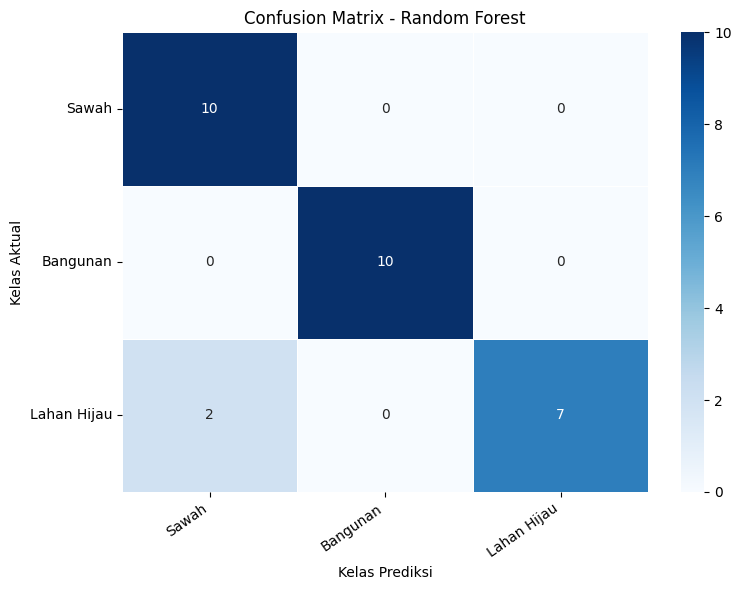


RINGKASAN JENIS KESALAHAN


,Kelas Aktual,Diprediksi Sebagai,Jumlah Kesalahan
0,Lahan Hijau,Sawah,2



EKSPOR HASIL
File hasil tersimpan di: /content/hasil_random_forest
ZIP hasil: /content/hasil_random_forest.zip

Model deployment: model_random_forest.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
import os
import shutil
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# 1. PERSIAPAN DATA & FITUR TAMBAHAN (NDVI, NDWI)
# ============================================================

if "df_dataset" not in globals():
    raise NameError(
        "df_dataset belum tersedia. Jalankan cell preprocessing terlebih dahulu."
    )

data_model = df_dataset.copy()

# Hitung NDVI dan NDWI jika belum ada di df_dataset
# NDVI = (B08 - B04) / (B08 + B04)
# NDWI = (B03 - B08) / (B03 + B08) (atau menggunakan B11 tergantung kebutuhan)
if "NDVI" not in data_model.columns:
    data_model["NDVI"] = (data_model["B08"] - data_model["B04"]) / (data_model["B08"] + data_model["B04"])

if "NDWI" not in data_model.columns:
    data_model["NDWI"] = (data_model["B03"] - data_model["B08"]) / (data_model["B03"] + data_model["B08"])

fitur_kolom = [
    "B02", "B03", "B04", "B08", "B11", "NDVI", "NDWI"
]

# Mapping kelas disesuaikan dengan data Anda (Sawah, Bangunan, Lahan Hijau)
nama_kelas = {
    0: "Sawah",
    1: "Bangunan",
    2: "Lahan Hijau"
}

label_urut = list(nama_kelas.keys())
nama_urut = list(nama_kelas.values())

kolom_dibutuhkan = fitur_kolom + ["Label"]

kolom_hilang = [
    kolom for kolom in kolom_dibutuhkan
    if kolom not in data_model.columns
]

if kolom_hilang:
    raise ValueError(
        f"Kolom berikut tidak ditemukan: {kolom_hilang}"
    )

# Pastikan fitur dan label berupa angka
for kolom in kolom_dibutuhkan:
    data_model[kolom] = pd.to_numeric(
        data_model[kolom], errors="coerce"
    )

data_model.replace([np.inf, -np.inf], np.nan, inplace=True)
data_model.dropna(subset=kolom_dibutuhkan, inplace=True)

# Hanya gunakan label bilangan bulat yang sesuai dengan mapping
data_model = data_model[
    data_model["Label"].isin(label_urut)
    & (data_model["Label"] % 1 == 0)
].copy()

data_model["Label"] = data_model["Label"].astype(int)

if data_model.empty:
    raise ValueError("Tidak ada data valid untuk pemodelan.")

# Periksa jumlah sampel setiap kelas
jumlah_kelas = (
    data_model["Label"]
    .value_counts()
    .reindex(label_urut, fill_value=0)
)

print("=" * 60)
print("PEMETAAN LABEL DAN DISTRIBUSI DATA")
print("=" * 60)

display(pd.DataFrame({
    "Label": label_urut,
    "Nama Kelas": nama_urut,
    "Jumlah Data": jumlah_kelas.values
}))

print("Total data valid:", len(data_model))

kelas_kurang = jumlah_kelas[jumlah_kelas < 2]

if not kelas_kurang.empty:
    raise ValueError(
        "Setiap kelas harus memiliki minimal 2 sampel. "
        f"Kelas yang kurang data: {kelas_kurang.to_dict()}"
    )

# ============================================================
# 2. PEMBAGIAN DATA TRAINING DAN TESTING
# ============================================================

print("\n" + "=" * 60)
print("PEMBAGIAN DATA TRAINING DAN TESTING")
print("=" * 60)

X = data_model[fitur_kolom].copy()
y = data_model["Label"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=21,
    stratify=y
)

print("Total data     :", len(data_model))
print("Data training  :", len(X_train))
print("Data testing   :", len(X_test))
print("Jumlah fitur   :", len(fitur_kolom))

print("\nDistribusi kelas training:")
display(
    y_train.value_counts()
    .reindex(label_urut, fill_value=0)
    .rename(index=nama_kelas)
    .rename("Jumlah")
    .to_frame()
)

print("Distribusi kelas testing:")
display(
    y_test.value_counts()
    .reindex(label_urut, fill_value=0)
    .rename(index=nama_kelas)
    .rename("Jumlah")
    .to_frame()
)

# ============================================================
# 3. TRAINING RANDOM FOREST
# ============================================================

print("\n" + "=" * 60)
print("TRAINING RANDOM FOREST")
print("=" * 60)

model_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    class_weight="balanced",
    random_state=21,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)

print("Training selesai.")
print("Fitur model:", list(model_rf.feature_names_in_))
print("Label model:", model_rf.classes_)

# ============================================================
# 4. EVALUASI PADA DATA TESTING
# ============================================================

print("\n" + "=" * 60)
print("EVALUASI RANDOM FOREST")
print("=" * 60)

y_pred = model_rf.predict(X_test)

akurasi = accuracy_score(y_test, y_pred)
jumlah_benar = int((y_test.to_numpy() == y_pred).sum())
jumlah_salah = len(y_test) - jumlah_benar

print("Jumlah data testing :", len(y_test))
print("Prediksi benar      :", jumlah_benar)
print("Prediksi salah      :", jumlah_salah)
print(f"Akurasi testing     : {akurasi * 100:.2f}%")

print("\nCLASSIFICATION REPORT")

laporan = classification_report(
    y_test,
    y_pred,
    labels=label_urut,
    target_names=nama_urut,
    output_dict=True,
    zero_division=0
)

display(pd.DataFrame(laporan).transpose().round(3))

# ============================================================
# 5. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=label_urut
)

tabel_cm = pd.DataFrame(
    cm,
    index=nama_urut,
    columns=nama_urut
)

print("\nCONFUSION MATRIX")
print("Baris = kelas aktual, kolom = kelas prediksi")

display(tabel_cm)

plt.figure(figsize=(8, 6))

sns.heatmap(
    tabel_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Kelas Prediksi")
plt.ylabel("Kelas Aktual")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ============================================================
# 6. RINGKASAN JENIS KESALAHAN
# ============================================================

print("\n" + "=" * 60)
print("RINGKASAN JENIS KESALAHAN")
print("=" * 60)

data_salah = pd.DataFrame({
    "Label Aktual": y_test.to_numpy(),
    "Label Prediksi": y_pred
})

data_salah = data_salah[
    data_salah["Label Aktual"] != data_salah["Label Prediksi"]
].copy()

if data_salah.empty:
    ringkasan_salah = pd.DataFrame(columns=[
        "Kelas Aktual",
        "Diprediksi Sebagai",
        "Jumlah Kesalahan"
    ])
    print("Tidak ada kesalahan pada data testing.")

else:
    ringkasan_salah = (
        data_salah
        .groupby(["Label Aktual", "Label Prediksi"])
        .size()
        .reset_index(name="Jumlah Kesalahan")
    )

    ringkasan_salah["Kelas Aktual"] = (
        ringkasan_salah["Label Aktual"].map(nama_kelas)
    )

    ringkasan_salah["Diprediksi Sebagai"] = (
        ringkasan_salah["Label Prediksi"].map(nama_kelas)
    )

    ringkasan_salah = (
        ringkasan_salah[[
            "Kelas Aktual",
            "Diprediksi Sebagai",
            "Jumlah Kesalahan"
        ]]
        .sort_values("Jumlah Kesalahan", ascending=False)
        .reset_index(drop=True)
    )

    display(ringkasan_salah)

# ============================================================
# 7. SIMPAN MODEL DAN HASIL EVALUASI
# ============================================================

print("\n" + "=" * 60)
print("EKSPOR HASIL")
print("=" * 60)

folder_hasil = "/content/hasil_random_forest"
os.makedirs(folder_hasil, exist_ok=True)

joblib.dump(
    model_rf,
    os.path.join(folder_hasil, "model_random_forest.pkl")
)

joblib.dump(
    nama_kelas,
    os.path.join(folder_hasil, "mapping_kelas.pkl")
)

pd.DataFrame(laporan).transpose().to_csv(
    os.path.join(folder_hasil, "classification_report.csv")
)

tabel_cm.to_csv(
    os.path.join(folder_hasil, "confusion_matrix.csv")
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    tabel_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Kelas Prediksi")
plt.ylabel("Kelas Aktual")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(
        folder_hasil,
        "confusion_matrix_random_forest.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

if not data_salah.empty:
    ringkasan_salah.to_csv(
        os.path.join(folder_hasil, "ringkasan_jenis_kesalahan.csv"),
        index=False
    )

hasil_testing = X_test.copy()
hasil_testing["Label Aktual"] = y_test
hasil_testing["Label Prediksi"] = y_pred
hasil_testing["Nama Aktual"] = y_test.map(nama_kelas)
hasil_testing["Nama Prediksi"] = pd.Series(
    y_pred, index=y_test.index
).map(nama_kelas)

hasil_testing.to_csv(
    os.path.join(folder_hasil, "hasil_testing.csv"),
    index=False
)

file_zip = shutil.make_archive(
    folder_hasil,
    "zip",
    folder_hasil
)

print("File hasil tersimpan di:", folder_hasil)
print("ZIP hasil:", file_zip)
print("\nModel deployment: model_random_forest.pkl")

files.download(file_zip)

---
# 4️⃣ Modeling
## 4.1 Mengapa Random Forest?
Random Forest adalah **kumpulan banyak pohon keputusan** yang masing-masing belajar dari sampel acak, lalu **memberi suara**. Cocok untuk kasus ini karena: tidak perlu normalisasi nilai band, mampu menangkap hubungan non-linear, relatif tahan *overfitting* dan data kecil, serta bisa menunjukkan fitur mana yang paling penting.

### a. Satu pohon keputusan
Sebuah pohon bertanya berurutan, misalnya *"NDVI > 0,5? B11 < 1500?"*, hingga sampai pada jawaban kelas. Pertanyaan terbaik dipilih dengan mengukur **kemurnian** simpul memakai **Gini impurity**:

$$G = 1 - \sum_{k=1}^{K} p_k^2$$

dengan $p_k$ = proporsi kelas $k$ di simpul itu. $G=0$ berarti simpul murni (satu kelas saja). Contoh: simpul berisi 50% Sawah dan 50% Hutan → $G = 1-(0{,}5^2+0{,}5^2) = 0{,}5$.

Sebuah pertanyaan dipilih bila **penurunan impurity**-nya paling besar:

$$\Delta G = G_{induk} - \left(\frac{n_{kiri}}{n}G_{kiri} + \frac{n_{kanan}}{n}G_{kanan}\right)$$

### b. Hutan = banyak pohon + voting
Setiap pohon dilatih dari **bootstrap sample** (ambil $n$ data dengan pengembalian, jadi ±63% data unik) dan pada tiap percabangan hanya mempertimbangkan $m=\sqrt{p}$ fitur acak. Ini membuat pohon-pohon **beragam**. Prediksi akhir adalah **suara terbanyak** dari $T$ pohon:

$$\hat{y}(x) = \operatorname{mode}\{\, h_1(x),\, h_2(x),\, \dots,\, h_T(x) \,\}$$

Dengan $p=7$ fitur, scikit-learn memakai $m=\lfloor\sqrt{7}\rfloor=2$ fitur acak di tiap percabangan. Data yang tidak terambil di bootstrap (±37%) disebut ***out-of-bag* (OOB)**. Data ini dipakai sebagai "ujian gratis" internal untuk mengestimasi akurasi tanpa menyentuh data uji.

### c. Menangani kelas yang jumlahnya timpang
Dengan `class_weight="balanced"`, kelas yang sampelnya sedikit diberi bobot lebih besar:

$$w_k = \frac{N}{K \cdot n_k}$$

($N$ = total sampel latih, $K$ = jumlah kelas, $n_k$ = sampel kelas $k$). Jadi kesalahan pada kelas kecil (mis. Danau) dihitung lebih "mahal".

## 4.2 Hyperparameter

| Parameter | Nilai | Arti |
|---|---|---|
| `n_estimators` | 300 | Jumlah pohon ($T$) |
| `max_depth` | None | Pohon boleh tumbuh sedalam yang diperlukan |
| `min_samples_split` | 2 | Minimal sampel agar simpul boleh dipecah |
| `min_samples_leaf` | 1 | Minimal sampel di daun |
| `max_features` | "sqrt" | $m=\sqrt{p}$ fitur per percabangan |
| `class_weight` | "balanced" | Bobot kelas seperti rumus di atas |
| `oob_score` | True | Hitung akurasi *out-of-bag* |
| `random_state` | 21 | Hasil dapat diulang |

=== 1. PERSIAPAN DATA & EKSTRAKSI PIKSEL ===
Membaca dan menggabungkan file data latih (6 kelas)...
Jumlah total sampel: 290

CRS raster: EPSG:4326
Jumlah band: 5
Ukuran raster: 3108 x 1330
Ekstraksi piksel selesai.

=== 2. TRAINING MODEL RANDOM FOREST ===
Training selesai.

=== 3. DEPLOYMENT & INFERENSI RASTER ===

STATISTIK HASIL KLASIFIKASI:


,Label,Kelas,Jumlah Piksel,Persentase (%)
0,0,Sawah,1389748,33.62
1,1,Bangunan,561389,13.58
2,2,Hutan,1081243,26.16
3,3,Mangrove,225799,5.46
4,4,Danau,39318,0.95
5,5,Lautan,836076,20.23


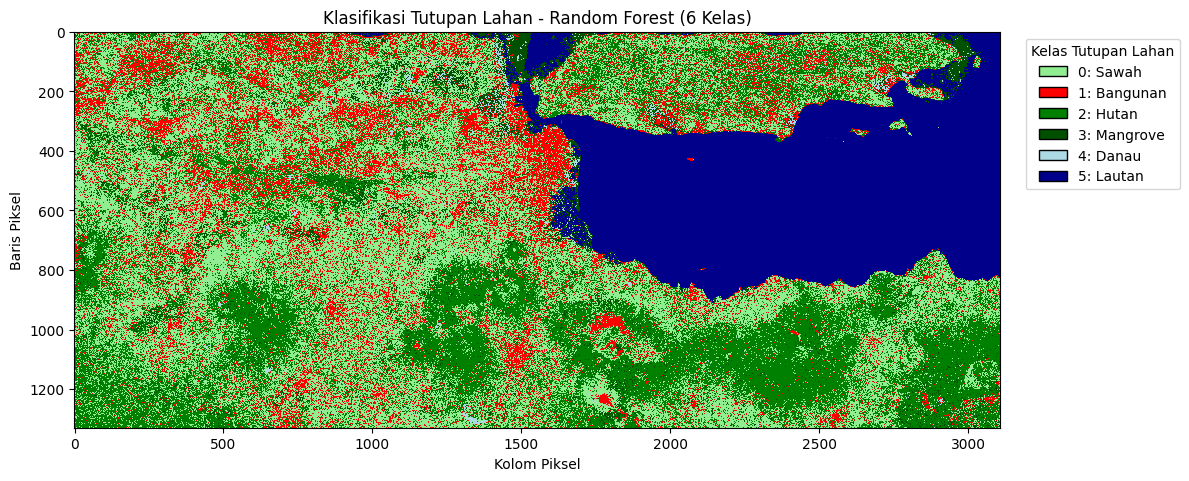


SELESAI! Semua file hasil telah diproses.
File ZIP tersimpan di: /content/hasil_deployment.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
import os
import shutil
import joblib
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from scipy import ndimage
from IPython.display import display

# ============================================================
# 1. PERSIAPAN DATA DAN EKSTRAKSI PIKSEL DARI 6 FILE
# ============================================================
print("=== 1. PERSIAPAN DATA & EKSTRAKSI PIKSEL ===")

file_raster = "/content/hasil_sentinel2/openEO.tif"

if not os.path.exists(file_raster):
    raise FileNotFoundError(f"Raster tidak ditemukan: {file_raster}")

# Membaca dan menggabungkan 6 file data latihan Anda
print("Membaca dan menggabungkan file data latih (6 kelas)...")
gdf_sawah = gpd.read_file("sawah_jawatimur.zip")
gdf_sawah["kelas"] = "Sawah"

gdf_bangunan = gpd.read_file("bangunan_jawatimur.zip")
gdf_bangunan["kelas"] = "Bangunan"

gdf_hutan = gpd.read_file("lahanhijau_jawatimur.geojson")
gdf_hutan["kelas"] = "Hutan"

gdf_mangrove = gpd.read_file("mangrove_jawatimur.zip")
gdf_mangrove["kelas"] = "Mangrove"

gdf_danau = gpd.read_file("danau_jawatimur.zip")
gdf_danau["kelas"] = "Danau"

gdf_lautan = gpd.read_file("perairanterbuka_jawatiur.zip")
gdf_lautan["kelas"] = "Lautan"

sampel = pd.concat([
    gdf_sawah, gdf_bangunan, gdf_hutan,
    gdf_mangrove, gdf_danau, gdf_lautan
], ignore_index=True)

if sampel.crs is None:
    sampel.set_crs("EPSG:4326", inplace=True)

print("Jumlah total sampel:", len(sampel))

# Mapping label numerik ke kelas (6 Kelas)
peta_label = {
    "Sawah": 0,
    "Bangunan": 1,
    "Hutan": 2,
    "Mangrove": 3,
    "Danau": 4,
    "Lautan": 5
}

sampel["Label"] = sampel["kelas"].map(peta_label)
kolom_kelas = "kelas"
kolom_label = "Label"

# Pastikan geometri valid
sampel = sampel[sampel.geometry.notna() & ~sampel.geometry.is_empty].copy()

with rasterio.open(file_raster) as src:
    print("\nCRS raster:", src.crs)
    print("Jumlah band:", src.count)
    print("Ukuran raster:", src.width, "x", src.height)

    if src.count < 5:
        raise ValueError("Raster harus memiliki minimal 5 band.")

    sampel_utm = sampel.to_crs(sampel.estimate_utm_crs())
    titik_utm = sampel_utm.geometry.centroid
    titik_raster = gpd.GeoSeries(titik_utm, crs=sampel_utm.crs).to_crs(src.crs)

    koordinat = list(zip(titik_raster.x, titik_raster.y))

    piksel = np.ma.vstack(list(src.sample(koordinat, masked=True)))
    nilai_band = piksel.astype(np.float32).filled(np.nan)

    for i, (x, y) in enumerate(koordinat):
        row, col = src.index(x, y)
        if not (0 <= row < src.height and 0 <= col < src.width):
            nilai_band[i, :] = np.nan

# Susun dataset awal
df_dataset = pd.DataFrame(
    nilai_band[:, :5],
    columns=["B02", "B03", "B04", "B08", "B11"]
)

df_dataset["Kelas"] = sampel[kolom_kelas].to_numpy()
df_dataset["Label"] = sampel[kolom_label].to_numpy()

titik_wgs84 = sampel_utm.geometry.centroid.to_crs("EPSG:4326")
df_dataset["Longitude"] = titik_wgs84.x.to_numpy()
df_dataset["Latitude"] = titik_wgs84.y.to_numpy()

print("Ekstraksi piksel selesai.\n")


# ============================================================
# 2. PELATIHAN MODEL RANDOM FOREST
# ============================================================
print("=== 2. TRAINING MODEL RANDOM FOREST ===")

data_model = df_dataset.copy()

# Hitung fitur tambahan NDVI dan NDWI
data_model["NDVI"] = (data_model["B08"] - data_model["B04"]) / (data_model["B08"] + data_model["B04"] + 1e-6)
data_model["NDWI"] = (data_model["B03"] - data_model["B08"]) / (data_model["B03"] + data_model["B08"] + 1e-6)

fitur_kolom = ["B02", "B03", "B04", "B08", "B11", "NDVI", "NDWI"]

nama_kelas = {
    0: "Sawah",
    1: "Bangunan",
    2: "Hutan",
    3: "Mangrove",
    4: "Danau",
    5: "Lautan"
}

label_urut = list(nama_kelas.keys())
nama_urut = list(nama_kelas.values())

kolom_dibutuhkan = fitur_kolom + ["Label"]
for kolom in kolom_dibutuhkan:
    data_model[kolom] = pd.to_numeric(data_model[kolom], errors="coerce")

data_model.replace([np.inf, -np.inf], np.nan, inplace=True)
data_model.dropna(subset=kolom_dibutuhkan, inplace=True)

data_model = data_model[
    data_model["Label"].isin(label_urut) & (data_model["Label"] % 1 == 0)
].copy()
data_model["Label"] = data_model["Label"].astype(int)

X = data_model[fitur_kolom].copy()
y = data_model["Label"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=21, stratify=y
)

model_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    class_weight="balanced",
    random_state=21,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)
print("Training selesai.")


# ============================================================
# 3. DEPLOYMENT / INFERENSI RASTER KESELURUHAN
# ============================================================
print("\n=== 3. DEPLOYMENT & INFERENSI RASTER ===")

folder_output = "/content/hasil_deployment"
os.makedirs(folder_output, exist_ok=True)

warna_rgb = {
    0: (144, 238, 144),  # Hijau Muda (Sawah)
    1: (255, 0, 0),      # Merah (Bangunan)
    2: (0, 128, 0),      # Hijau Tua (Hutan)
    3: (0, 80, 0),       # Hijau Gelap (Mangrove)
    4: (173, 216, 230),  # Biru Muda (Danau)
    5: (0, 0, 139)       # Biru Tua (Lautan)
}

with rasterio.open(file_raster) as src:
    tinggi = src.height
    lebar = src.width
    profil = src.profile.copy()
    nodata_sumber = src.nodata

    band_diperlukan = ["B02", "B03", "B04", "B08", "B11"]
    deskripsi_band = list(src.descriptions or ())
    indeks_band = {band: deskripsi_band.index(band) + 1 for band in band_diperlukan}

    hasil_prediksi = np.full((tinggi, lebar), 255, dtype=np.uint8)
    ukuran_blok = 512

    for row_start in range(0, tinggi, ukuran_blok):
        for col_start in range(0, lebar, ukuran_blok):
            tinggi_blok = min(ukuran_blok, tinggi - row_start)
            lebar_blok = min(ukuran_blok, lebar - col_start)
            window = rasterio.windows.Window(col_start, row_start, lebar_blok, tinggi_blok)

            data_band = {}
            for nama, nomor in indeks_band.items():
                data_band[nama] = src.read(nomor, window=window).astype(np.float32)

            mask_valid = np.ones((tinggi_blok, lebar_blok), dtype=bool)
            for nama in indeks_band:
                nilai = data_band[nama]
                mask_valid &= np.isfinite(nilai) & (nilai != -32768)
                if nodata_sumber is not None:
                    if np.isnan(nodata_sumber):
                        mask_valid &= ~np.isnan(nilai)
                    else:
                        mask_valid &= nilai != nodata_sumber

            B03 = data_band["B03"]
            B04 = data_band["B04"]
            B08 = data_band["B08"]

            NDVI = (B08 - B04) / (B08 + B04 + 1e-6)
            NDWI = (B03 - B08) / (B03 + B08 + 1e-6)

            mask_valid &= np.isfinite(NDVI) & np.isfinite(NDWI)
            if not np.any(mask_valid):
                continue

            X_blok = pd.DataFrame({
                "B02": data_band["B02"][mask_valid],
                "B03": data_band["B03"][mask_valid],
                "B04": data_band["B04"][mask_valid],
                "B08": data_band["B08"][mask_valid],
                "B11": data_band["B11"][mask_valid],
                "NDVI": NDVI[mask_valid],
                "NDWI": NDWI[mask_valid]
            })

            prediksi = model_rf.predict(X_blok[fitur_kolom])
            blok_hasil = hasil_prediksi[row_start:row_start + tinggi_blok, col_start:col_start + lebar_blok]
            blok_hasil[mask_valid] = prediksi.astype(np.uint8)


# ============================================================
# 4. KOREKSI KELAS DANAU & LAUTAN SERTA EKSPOR HASIL
# ============================================================
LUAS_MIN_LAUT = 5000
LUAS_MIN_TEPI = 200

mask_air = np.isin(hasil_prediksi, [4, 5])
label_air, jumlah_air = ndimage.label(mask_air, structure=np.ones((3, 3), dtype=int))

if jumlah_air > 0:
    luas_air = np.bincount(label_air.ravel())
    id_tepi = np.unique(np.concatenate([
        label_air[0, :], label_air[-1, :],
        label_air[:, 0], label_air[:, -1]
    ]))
    menyentuh_tepi = np.zeros(jumlah_air + 1, dtype=bool)
    menyentuh_tepi[id_tepi] = True

    komponen_laut = (luas_air >= LUAS_MIN_LAUT) | (menyentuh_tepi & (luas_air >= LUAS_MIN_TEPI))
    komponen_laut[0] = False
    mask_laut = komponen_laut[label_air]

    hasil_prediksi[mask_air & mask_laut] = 5
    hasil_prediksi[mask_air & ~mask_laut] = 4

# Simpan GeoTIFF
output_tif = os.path.join(folder_output, "hasil_klasifikasi_lulc.tif")
profil.update(driver="GTiff", count=1, dtype="uint8", nodata=255, compress="lzw")
with rasterio.open(output_tif, "w", **profil) as dst:
    dst.write(hasil_prediksi, 1)
    dst.set_band_description(1, "Kelas LULC")

# Statistik
mask_valid_final = hasil_prediksi != 255
total_piksel = int(mask_valid_final.sum())
statistik = []

for label, nama in nama_kelas.items():
    jumlah = int(np.sum(hasil_prediksi == label))
    persentase = (jumlah / total_piksel * 100) if total_piksel > 0 else 0
    statistik.append({
        "Label": label,
        "Kelas": nama,
        "Jumlah Piksel": jumlah,
        "Persentase (%)": round(persentase, 2)
    })

df_statistik = pd.DataFrame(statistik)
print("\nSTATISTIK HASIL KLASIFIKASI:")
display(df_statistik)
df_statistik.to_csv(os.path.join(folder_output, "statistik_klasifikasi.csv"), index=False)

# Visualisasi Peta Klasifikasi
warna_urut = [np.array(warna_rgb[i], dtype=float) / 255 for i in range(6)]
cmap = ListedColormap(warna_urut)
cmap.set_bad("white")
norm = BoundaryNorm(np.arange(-0.5, 6.5, 1), cmap.N)

peta_masked = np.ma.masked_equal(hasil_prediksi, 255)
fig, ax = plt.subplots(figsize=(12, 9))
ax.imshow(peta_masked, cmap=cmap, norm=norm, interpolation="nearest")

legenda = [
    Patch(facecolor=np.array(warna_rgb[i]) / 255, edgecolor="black", label=f"{i}: {nama_kelas[i]}")
    for i in range(6)
]
ax.legend(handles=legenda, title="Kelas Tutupan Lahan", loc="upper left", bbox_to_anchor=(1.02, 1))
ax.set_title("Klasifikasi Tutupan Lahan - Random Forest (6 Kelas)")
ax.set_xlabel("Kolom Piksel")
ax.set_ylabel("Baris Piksel")
plt.tight_layout()

output_png = os.path.join(folder_output, "peta_klasifikasi_lulc.png")
plt.savefig(output_png, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Kompresi ZIP dan Unduh File
file_zip = shutil.make_archive("/content/hasil_deployment", "zip", root_dir=folder_output)

print("\nSELESAI! Semua file hasil telah diproses.")
print("File ZIP tersimpan di:", file_zip)
files.download(file_zip)

---
# 5️⃣ Evaluation

## 5.1 Metrik evaluasi (rumus)
Dari **confusion matrix**, untuk tiap kelas $k$ didefinisikan: $TP_k$ (benar diprediksi kelas $k$), $FP_k$ (kelas lain diprediksi $k$), $FN_k$ (kelas $k$ diprediksi kelas lain).

| Metrik | Rumus | Arti sehari-hari |
|---|---|---|
| **Akurasi** (*Overall Accuracy*) | $\dfrac{\sum_k TP_k}{N}$ | Dari semua tebakan, berapa persen yang benar |
| **Precision** (*User's Accuracy*) | $\dfrac{TP_k}{TP_k + FP_k}$ | Saat model bilang "ini kelas $k$", seberapa sering benar |
| **Recall** (*Producer's Accuracy*) | $\dfrac{TP_k}{TP_k + FN_k}$ | Dari semua yang sebenarnya kelas $k$, berapa persen berhasil ditemukan |
| **F1-score** | $\dfrac{2 \cdot P_k \cdot R_k}{P_k + R_k}$ | Rata-rata harmonik precision dan recall |
| **F1-macro** | $\dfrac{1}{K}\sum_{k} F1_k$ | Rata-rata F1 semua kelas (adil bagi kelas kecil) |
| **Kappa (Cohen)** | $\dfrac{p_o - p_e}{1 - p_e}$ | Akurasi setelah dikoreksi kebetulan; $p_o$ = akurasi, $p_e=\sum_k \dfrac{a_k b_k}{N^2}$ |
